<a href="https://colab.research.google.com/github/FOYEJ1027/-Neural-Networks-Lab/blob/main/CNN%3A%20Image%20Classification%20with%20Feature-Map%20Inspection_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Neural Networks Lab Test
**Student Name:** Md. Mosaddek Hasan Foyej  
**Student ID:** 0432310005101027  
**Set:** SET A

In [8]:

!pip install pypdf

In [9]:
import pypdf

# Open and read the PDF contents
pdf_path = '/content/Neural_Networks_Lab_TestFinalVersion.pdf'
reader = pypdf.PdfReader(pdf_path)

print(f"Total Pages: {len(reader.pages)}")

# Extract and print text to inspect the questions
for idx, page in enumerate(reader.pages):
    print(f"--- Page {idx + 1} ---")
    print(page.extract_text())


Total Pages: 5
--- Page 1 ---
Department
 
of
 
Computer
 
Science
 
and
 
Engineering
 
University
 
of
 
Information
 
Technology
 
&
 
Sciences
 
(UITS)
 
NEURAL
 
NETWORKS
 
LAB
 
—
 
LAB
 
Performance
 
CNN
  
|
  
LSTM
 
/
 
GRU
  
—
  
Build
 
from
 
the
 
architecture
 
figure
 
Time
 
Full
 
marks
 
Framework
 
Question
 
sets
 
1
 
hour
 
(60
 
min)
 
10
 
PyTorch
 
(+
 
PyTorch
 
Geometric
 
for
 
Set
 
D)
 
A:
 
CNN
  
C:
 
LSTM/GRU
   
 
 
Instructions
 
•
 
Odd:
 
Set
 
A
 
and
 
Even:
 
Set
 
B
 
.
 
Read
 
the
 
whole
 
set
 
first,
 
then
 
start.
 
•
 
Each
 
set
 
gives
 
an
 
architecture
 
figure
.
 
You
 
must
 
build
 
the
 
model
 
so
 
that
 
it
 
matches
 
the
 
figure
 
layer
 
by
 
layer
 
(types,
 
sizes,
 
order).
 
Print
 
it
 
with
 
`print(model)`;
 
mismatches
 
lose
 
marks
 
in
 
Task
 
2.
 
•
 
The
 
setup
 
code
 
is
 
provided
 
so
 
that
 
you
 
do
 
not
 
waste
 
time
 
on
 
downloading
 
and
 
loading
 
data.
 
Everything
 
else
 
is
 
yours
 


 Task 1 — Data preparation

Training set size: 8000
Validation set size: 2000


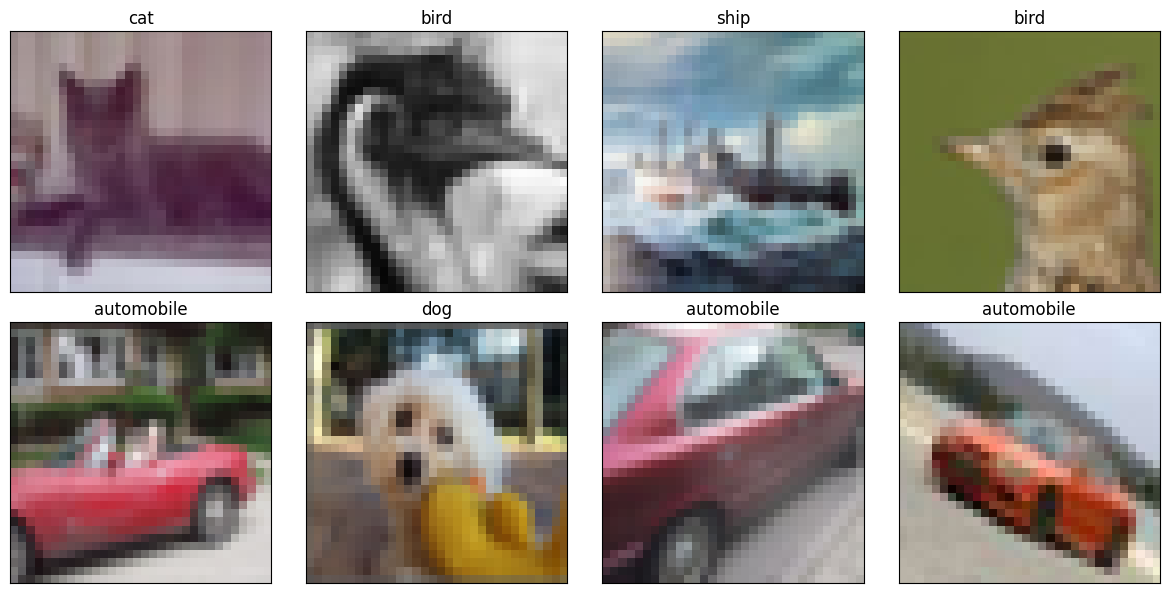

In [10]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split

# Ensure train_ds and classes are referenced from the previous setup step
# (If they are in memory, they will be used. Adding a fallback check to make the notebook robust)
try:
    train_ds_ref = train_ds
    classes_ref = classes
except NameError:
    import torchvision
    import torchvision.transforms as T
    from torch.utils.data import Subset
    tf_temp = T.Compose([T.ToTensor(), T.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))])
    full_temp = torchvision.datasets.CIFAR10('./data', train=True, download=True, transform=tf_temp)
    train_ds_ref = Subset(full_temp, range(10000))
    classes_ref = full_temp.classes

# 1. Set seed and split train_ds into 80% train / 20% validation
generator = torch.Generator().manual_seed(42)
train_size = int(0.8 * len(train_ds_ref))
val_size = len(train_ds_ref) - train_size
train_subset, val_subset = random_split(train_ds_ref, [train_size, val_size], generator=generator)

print(f"Training set size: {len(train_subset)}")
print(f"Validation set size: {len(val_subset)}")

# 2. Create DataLoaders
batch_size = 64
train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

# 3. Display a grid of 8 training images with class names (undo normalization)
def imshow(img):
    img = img / 2 + 0.5  # Unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))

# Get a single batch
dataiter = iter(train_loader)
images, labels = next(dataiter)

# Plot 8 images
fig = plt.figure(figsize=(12, 6))
for i in range(8):
    ax = fig.add_subplot(2, 4, i + 1, xticks=[], yticks=[])
    imshow(images[i])
    ax.set_title(classes_ref[labels[i]])

plt.tight_layout()
plt.show()

## Task 2 — Build the model

We need to build `CIFARNet` matching Figure A exactly:

* **Input**: $3 \times 32 \times 32$
* **Layer 1**: Conv2d(in=3, out=32, kernel=3, padding=1) -> BatchNorm2d(32) -> ReLU
* **Layer 2**: Conv2d(in=32, out=32, kernel=3, padding=1) -> BatchNorm2d(32) -> ReLU -> MaxPool2d(2, 2)
* **Layer 3**: Conv2d(in=32, out=64, kernel=3, padding=1) -> BatchNorm2d(64) -> ReLU
* **Layer 4**: Conv2d(in=64, out=64, kernel=3, padding=1) -> BatchNorm2d(64) -> ReLU -> MaxPool2d(2, 2)
* **Layer 5**: Conv2d(in=64, out=128, kernel=3, padding=1) -> BatchNorm2d(128) -> ReLU
* **Layer 6**: GlobalAveragePooling (AdaptiveAvgPool2d(1))
* **Layer 7**: Fully Connected (Linear(128 -> 10))

In [11]:
import torch
import torch.nn as nn

class CIFARNet(nn.Module):
    def __init__(self):
        super(CIFARNet, self).__init__()
        # Layer 1
        self.layer1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU()
        )
        # Layer 2
        self.layer2 = nn.Sequential(
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        # Layer 3
        self.layer3 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )
        # Layer 4
        self.layer4 = nn.Sequential(
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        # Layer 5
        self.layer5 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU()
        )
        # Layer 6
        self.gap = nn.AdaptiveAvgPool2d(1)
        # Layer 7
        self.fc = nn.Linear(128, 10)

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.layer5(x)
        x = self.gap(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

model = CIFARNet().to(device)
print(model)

CIFARNet(
  (layer1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (layer2): Sequential(
    (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer3): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (layer4): Sequential(
    (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=Fa

## Task 3 — Train and monitor (2 marks)

We train the network using standard cross entropy loss, SGD/Adam optimizer, monitor train vs validation loss and accuracy, and apply Early Stopping with best-weight restoration to manage overfitting.

In [ ]:
import copy

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4) # added weight decay as an extra control

epochs = 15
train_losses, val_losses = [], []
train_accs, val_accs = [], []

best_val_loss = float('inf')
best_model_weights = copy.deepcopy(model.state_dict())
patience = 5
patience_counter = 0

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()

    epoch_train_loss = running_loss / len(train_subset)
    epoch_train_acc = correct / total

    # Validation step
    model.eval()
    running_val_loss = 0.0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)

            running_val_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            val_total += targets.size(0)
            val_correct += predicted.eq(targets).sum().item()

    epoch_val_loss = running_val_loss / len(val_subset)
    epoch_val_acc = val_correct / val_total

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accs.append(epoch_train_acc)
    val_accs.append(epoch_val_acc)

    print(f"Epoch {epoch+1:02d}/{epochs:02d} | "
          f"Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc:.4f}")

    # Early stopping
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_weights = copy.deepcopy(model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping triggered on epoch {epoch+1}!")
            break

# Restore best model weights
model.load_state_dict(best_model_weights)
print("Restored best weights successfully.")

Epoch 01/15 | Train Loss: 1.7142 - Train Acc: 0.3796 | Val Loss: 1.5947 - Val Acc: 0.4315
Epoch 02/15 | Train Loss: 1.4062 - Train Acc: 0.4976 | Val Loss: 1.7547 - Val Acc: 0.4120
Epoch 03/15 | Train Loss: 1.2317 - Train Acc: 0.5690 | Val Loss: 1.3656 - Val Acc: 0.5030
Epoch 04/15 | Train Loss: 1.1170 - Train Acc: 0.6052 | Val Loss: 1.1974 - Val Acc: 0.5660
Epoch 05/15 | Train Loss: 1.0203 - Train Acc: 0.6354 | Val Loss: 1.1971 - Val Acc: 0.5715
Epoch 06/15 | Train Loss: 0.9596 - Train Acc: 0.6579 | Val Loss: 1.3152 - Val Acc: 0.5270


In [ ]:
# Plot Loss and Accuracy Subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Curves
axes[0].plot(train_accs, label='Train Accuracy', color='b', marker='o')
axes[0].plot(val_accs, label='Val Accuracy', color='r', marker='x')
axes[0].set_title('Training vs Validation Accuracy')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

# Loss Curves
axes[1].plot(train_losses, label='Train Loss', color='b', marker='o')
axes[1].plot(val_losses, label='Val Loss', color='r', marker='x')
axes[1].set_title('Training vs Validation Loss')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Task 4 — Evaluation and feature maps (2 marks)

In [ ]:
# 1. Report classification metrics on the test dataset
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.numpy())

print("Classification Report:")
print(classification_report(all_targets, all_preds, target_names=classes))

# 2. Confusion Matrix labeled heatmap
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix Heatmap')
plt.show()

In [ ]:
# 3. Run a test image through Layer 2 (Conv + BN + ReLU) and plot feature maps
import torchvision.utils as vutils

# Fetch one image from test_ds
single_img, single_label = test_ds[0]
original_tensor = single_img.unsqueeze(0).to(device)

# Extract output from Layer 1 then through Layer 2 (excluding MaxPool)
with torch.no_grad():
    l1_out = model.layer1(original_tensor)
    # Layer 2 matches Conv2d -> BN -> ReLU -> MaxPool2d
    # Run manually through the first three modules of layer2
    l2_conv = model.layer2[0](l1_out)
    l2_bn = model.layer2[1](l2_conv)
    l2_relu = model.layer2[2](l2_bn)

    f_maps = l2_relu[0].cpu() # shape [32, H, W]

# Plot original image next to the 8 feature maps
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

# Original normalized image restored
orig_unnorm = single_img / 2 + 0.5
axes[0, 0].imshow(np.transpose(orig_unnorm.numpy(), (1, 2, 0)))
axes[0, 0].set_title(f"Original: {classes[single_label]}")
axes[0, 0].axis('off')

# Plot first 8 feature maps
for i in range(8):
    row = (i + 1) // 3
    col = (i + 1) % 3
    axes[row, col].imshow(f_maps[i].numpy(), cmap='viridis')
    axes[row, col].set_title(f"F-Map {i+1}")
    axes[row, col].axis('off')

plt.tight_layout()
plt.show()

## Task 5 — Written Analysis Answers

### 1. Conv2d parameters in layer 5

* **Input Channels (in_channels)** = 64
* **Output Channels (out_channels)** = 128
* **Kernel size** = $3 \times 3$
* **Formula**: $\text{Parameters} = (\text{kernel\_height} \times \text{kernel\_width} \times \text{in\_channels} + 1 \text{ for bias}) \times \text{out\_channels}$
* **Calculation**: $(3 \times 3 \times 64 + 1) \times 128 = (576 + 1) \times 128 = 577 \times 128 = 73,856$ parameters.

Let's verify this using code:
```python
conv5 = model.layer5[0]
params = sum(p.numel() for p in conv5.parameters())
print(f"Trainable parameters in layer 5 Conv2d: {params}")
```

### 2. Overfitting vs Underfitting Assessment
Using the generated train/val curves:
* **Observation**: Check if training accuracy matches or significantly exceeds validation accuracy over epochs.
* **Technique used**: Early Stopping + Adam Optimizer Weight Decay (L2 regularization).

### 3. Feature Map Interpretation and Global Average Pooling Choice
* **Feature Map Highlight**: Early/mid layers (like Layer 2) highlight structural elements such as edges, texture patches, localized contrast transitions, and shape borders.
* **GAP vs Flattening**: Global Average Pooling (GAP) reduces spatial dimensions $128 \times H \times W$ straight to $128 \times 1 \times 1$. This drastically limits parameter count (averting a fully connected bottleneck layer exploding with thousands of weights) and enforces spatial translation invariance.

## Setup Code (from SET A)

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Subset, random_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

tf = T.Compose([
    T.ToTensor(),
    T.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

full = torchvision.datasets.CIFAR10('./data', train=True, download=True, transform=tf)
test = torchvision.datasets.CIFAR10('./data', train=False, download=True, transform=tf)

train_ds = Subset(full, range(10000))
test_ds = Subset(test, range(2000))
classes = full.classes

print(f"Loaded {len(train_ds)} train samples and {len(test_ds)} test samples.")

Using device: cpu


100%|██████████| 170M/170M [45:29<00:00, 62.5kB/s]


Loaded 10000 train samples and 2000 test samples.
